In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Yuan2018_Brain | category: Brain


In [ ]:
# load dataset -> select malignant cells
# High-Grade Glioma, Microwell array-based platform (UMI counts -> normalize_total -> log1p by loader).
# leaf-dir walk (merge.py convention): one leaf here, no nested technology subdirs.
leaves = [dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0]
print('leaf matrix dirs:', [os.path.basename(l) for l in leaves])
adata = load_CCCA_adata(leaves[0])
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
adata

leaf matrix dirs: ['Data_Yuan2018_Brain']
Loading ../../../../../../data/unzip/CCCA/Data_Yuan2018_Brain
Done.
full atlas: (23793, 58828)
malignant: (20080, 58828) | samples: 8
expression: X max 5.64 (log1p of normalize_total UMI counts)


AnnData object with n_obs × n_vars = 20080 × 58828
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'clusters', 'clusters_malignant_cells', 'celltype'
    uns: 'log1p'

In [ ]:
# per-sample malignant counts -> data-driven threshold (no anchor constant, C1).
# rule: largest multiplicative gap = a cliff; cut at its geometric mean ONLY if it isolates a
# genuinely sparse tail (small side below the ~100-cell floor). premise (C3) checked explicitly.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); lo_side = vals[gap+1]
geo = int(np.sqrt(vals[gap]*vals[gap+1])); FLOOR = 100
print('sorted per-sample counts:', n.values.astype(int).tolist())
print('adjacent ratios         :', np.round(ratios, 2).tolist())
print(f'largest gap {int(vals[gap])} -> {int(lo_side)} (ratio {ratios[gap]:.2f}); geometric-mean cut = {geo}')
if lo_side < FLOOR:
    thresh = geo
    print(f'C3 premise MET: small side {int(lo_side)} < {FLOOR} floor -> sparse tail -> cut at {thresh}')
else:
    thresh = FLOOR
    print(f'C3 premise NOT met: small side {int(lo_side)} >> {FLOOR} floor (well-sampled tumours, not a')
    print(f'   sparse tail) -> fall back to >={FLOOR} floor (Bischoff precedent); keep all samples above floor.')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (min per-sample = {int(n[n>=thresh].min())})')
adata

sorted per-sample counts: [5420, 3085, 3083, 2999, 2310, 2012, 598, 573]
adjacent ratios         : [1.76, 1.0, 1.03, 1.3, 1.15, 3.36, 1.04]
largest gap 2012 -> 598 (ratio 3.36); geometric-mean cut = 1096
C3 premise NOT met: small side 598 >> 100 floor (well-sampled tumours, not a
   sparse tail) -> fall back to >=100 floor (Bischoff precedent); keep all samples above floor.
kept 8/8 samples -> 20080 cells (min per-sample = 573)


AnnData object with n_obs × n_vars = 20080 × 58828
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'clusters', 'clusters_malignant_cells', 'celltype'
    uns: 'log1p'

In [ ]:
# filter genes -> overdispersed selection (data-driven, scFates GAM) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2).tolist())
# scree elbow sits low (PC1 dominates); the eval audit flags a low elbow as under-powering the
# manifold into a patient-segregated read. Bound to the precedent range (Kurten 20, Puram 40; all
# successful autonomous runs used n_pcs=20) -> n_pcs = 20.
NPCS = 20
print('n_pcs =', NPCS, '(scree elbow low, rejected as under-powering; bounded to precedent, eval audit)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 729 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 729
PC variance% (1-12): [11.13, 7.71, 3.68, 3.17, 2.13, 1.91, 1.77, 1.49, 1.34, 1.12, 1.01, 0.9]
n_pcs = 20 (scree elbow low, rejected as under-powering; bounded to precedent, eval audit)


In [ ]:
# integrate samples with Harmony -> choose theta by per-neighbourhood mixing (iLISI), not a scalar.
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
print(f'iLISI median (of {nsamp} samples): pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v, 2) for k, v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing rises monotonically, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

iLISI median (of 8 samples): pre-Harmony 1.00 | sweep {2: np.float64(2.75), 5: np.float64(3.83), 10: np.float64(4.08)}
selected theta = 10 (mixing rises monotonically, no collapse)


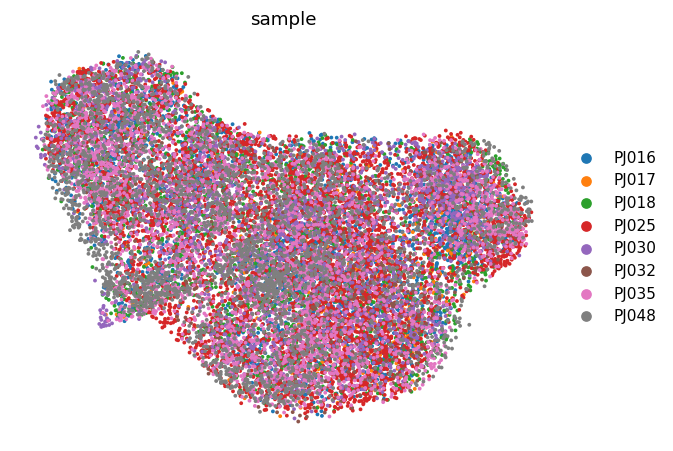

In [ ]:
# Gate-1 evidence #1 - the regenerated embedding, coloured by sample (judged on the embedding itself).
sc.pl.umap(adata, color='sample', size=25, frameon=False)

In [ ]:
# remove detached islands: UMAP radius-graph (6x median NN), keep the largest component.
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'radius-graph components: {ncomp}; largest = {int((lab==main).sum())} cells')
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(1 = continuous)')

radius-graph components: 1; largest = 20080 cells
removed 0 cells in 0 detached islands
kNN connectivity components: 1 (1 = continuous)


lobe sizes    : {'0': 7078, '1': 10025, '2': 2977}
cycling / lobe: {'0': 0.08, '1': 0.1, '2': 0.09}
overall cycling fraction: 0.088


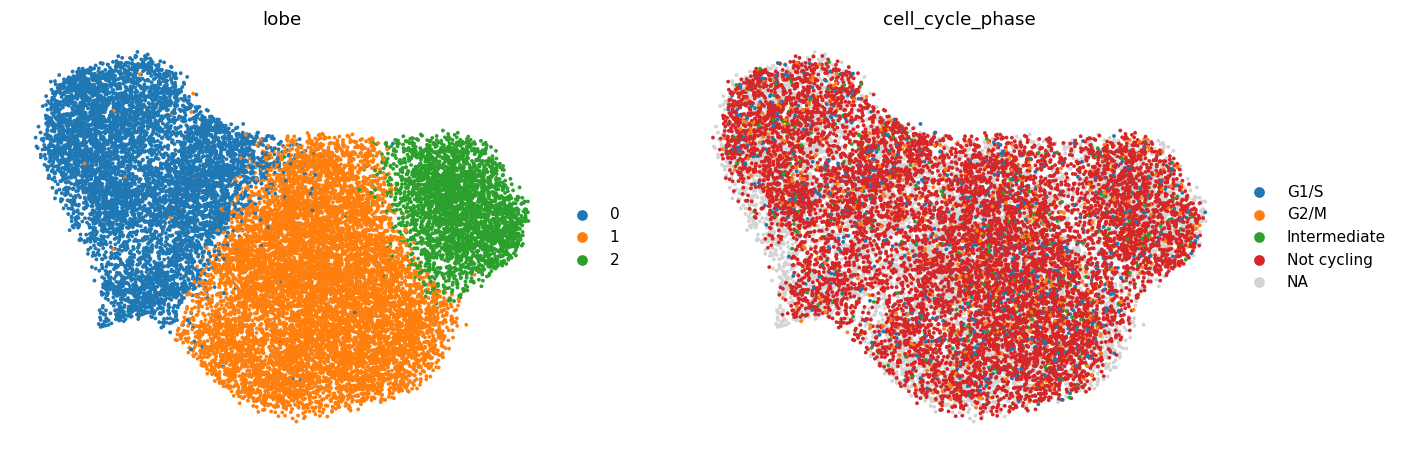

In [ ]:
# Gate-1 evidence #2 - sub-region biology BEFORE the GO (Kurten lobe-identity fork).
# coarse Leiden lobes + cell-cycle: is any lobe a distinct lineage or a proliferation confound?
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes    :', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling / lobe:', cyc.round(2).to_dict())
print('overall cycling fraction:', round(adata.obs['cycling'].mean(), 3))
sc.pl.umap(adata, color=['lobe', 'cell_cycle_phase'], size=25, frameon=False)

In [ ]:
# orient the embedding to the house convention: rigid rotation onto the major axis, developmental
# origin (Gast/pSom-high) on the LEFT. distances preserved (X_umap_lin).
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name='_'+lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
origin = (adata.obs['_Gast'] + adata.obs['_pSom']).values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0, 1], vt[0, 0])
Rm = np.array([[np.cos(-th), -np.sin(-th)], [np.sin(-th), np.cos(-th)]])
xyr = c @ Rm.T
if np.average(xyr[:, 0], weights=(origin - origin.min() + 1e-9)) > 0:
    xyr[:, 0] = -xyr[:, 0]
adata.obsm['X_umap_lin'] = xyr
adata.obs.drop(columns=['_Gast', '_pSom'], inplace=True)
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th):+.1f}deg, origin pole on left -> X_umap_lin')

manifold aspect (max/min std): 1.63
house orientation: rigid rotation -17.4deg, origin pole on left -> X_umap_lin


In [ ]:
# tidy obs dtypes -> save processed manifold
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (20080, 36009)


saved samples.pdf | cells: 20080


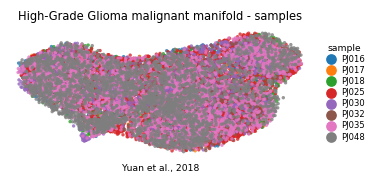

In [ ]:
# deliverable: samples.pdf - house style (3.5,1.5 horizontal strip), house orientation.
# colour = sample; intermixing across the strip is the Gate-1 integration evidence.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=20, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('High-Grade Glioma malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Yuan et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])